In [76]:
from config import *
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table, join

## Load in Tables and Specified Columns

| DMU (table) | Column | Description | Units |
| --- | --- | --- | --- |
| SpecObjv27 | CATAID | Catalouge ID |  |
|  | SPECID | Identifies best spectrum |  |
|  | RA, DEC | Sky angular position | degrees |
|  | Z | Redshift |  |
|  | NQ | Redshift quality factor |  |
| StellarMassesLambdarv24 | CATAID | Catalouge ID |  |
|  | logmstar | Log of the stellar mass | log($M_\odot$) |
|  | dellogmstar | 1 $\sigma$ error on logmstar | log($M_\odot$) |
|  | absmag_r | r-band absolute magnitude | mag |
|  | delabsmag_r | 1 $\sigma$ error on absmag_r | mag |
| MagPhysv06 | CATAID | Catalouge ID |  |
|  | SFR_0_1Gyr_percentile50 | Median SFR averaged over 100 Myr | log($M_\odot$/yr) |
|  | SFR_0_1Gyr_percentile16, SFR_0_1Gyr_percentile84 | 1 $\sigma$ range of the SFR posterior | log($M_\odot$/yr) |
| GaussFitSimplev05 | CATAID | Catalouge ID |  |
|  | SPECID | Spectrum ID |  |
|  | HA_FLUX, HA_FLUX_ERR | H$\alpha$ flux and error | $10^{-17}$ erg/s/cm^2 |
|  | HA_EW, HA_EW_ERR | H$\alpha$ equivalent width and error | $\AA$ |
|  | HB_FLUX, HB_FLUX_ERR | H$\beta$ flux and error | $10^{-17}$ erg/s/cm^2 |
|  | NIIR_FLUX, NIIR_FLUX_ERR | NII flux and error | $10^{-17}$ erg/s/cm^2 |
|  | OIIIR_FLUX, OIIIR_FLUX_ERR | OIII flux and error | $10^{-17}$ erg/s/cm^2 |

In [77]:
def load(path, cols):
    """
    Load a table from a file and return only the specified columns.

    Parameters
    ----------
    path : str
        Path to the file to load.
    cols : list of str
        List of column names to return.

    Returns
    -------
    astropy.table.Table
        Table containing only the specified columns.
    """

    table = Table.read(path, unit_parse_strict = 'silent')
    table.meta.clear()
    return table[cols]

In [78]:
SpecObj = load('data/SpecObjv27.fits', ['CATAID', 'SPECID', 'RA', 'DEC', 'Z', 'NQ'])

StellarMassesLambdar = load('data/StellarMassesLambdarv24.fits',
          ['CATAID', 'logmstar', 'dellogmstar', 'absmag_r', 'delabsmag_r'])

MagPhys = load('data/MagPhysv06.fits',
          ['CATAID', 'SFR_0_1Gyr_percentile16', 'SFR_0_1Gyr_percentile50', 'SFR_0_1Gyr_percentile84'])

GaussFitSimple = load('data/GaussFitSimplev05.fits',
          ['CATAID', 'SPECID', 'HA_FLUX', 'HA_FLUX_ERR', 'HA_EW', 'HA_EW_ERR', 'HB_FLUX', 'HB_FLUX_ERR', 'NIIR_FLUX', 'NIIR_FLUX_ERR', 'OIIIR_FLUX', 'OIIIR_FLUX_ERR'])

# Check for duplicate CATAIDs in each table
for name, t in [('SpecObjv27', SpecObj), ('StellarMassesLambdarv24', StellarMassesLambdar), ('MagPhysv06', MagPhys), ('GaussFitSimplev05', GaussFitSimple)]:
    n_dup = len(t) - len(np.unique(t['CATAID']))
    print(f'{name}: {len(t)} rows, {n_dup} duplicate CATAIDs')

SpecObjv27: 344905 rows, 0 duplicate CATAIDs
StellarMassesLambdarv24: 200077 rows, 0 duplicate CATAIDs
MagPhysv06: 197494 rows, 0 duplicate CATAIDs
GaussFitSimplev05: 427829 rows, 122297 duplicate CATAIDs


## Merge Tables

In [79]:
# Merge the tables into a single catalogue
catalogue = join(SpecObj, StellarMassesLambdar, keys = 'CATAID', join_type = 'inner')
catalogue = join(catalogue, MagPhys, keys = 'CATAID', join_type = 'left') # SFR may be missing for galaxies counted as neighbours
GaussFitSimple_best = GaussFitSimple[np.isin(GaussFitSimple['SPECID'], SpecObj['SPECID'])] # Only keep rows with the best spectrum
catalogue = join(catalogue, GaussFitSimple_best, keys = ['CATAID', 'SPECID'], join_type = 'left')

# Turn masked values into NaN
for col in catalogue.colnames:
    if hasattr(catalogue[col], 'mask') and catalogue[col].dtype.kind == 'f':
        catalogue[col] = catalogue[col].filled(np.nan)

# Check for duplicate CATAIDs in the final catalogue
n_dup = len(catalogue) - len(np.unique(catalogue['CATAID']))
print(f'Full catalogue: {len(catalogue)} rows, {n_dup} duplicate CATAIDs')

Full catalogue: 200077 rows, 0 duplicate CATAIDs


## Perform Cuts

In [80]:
# Filter the catalogue to create the parent sample
keep = ((catalogue['Z'] >= Z_MIN) & (catalogue['Z'] <= Z_MAX)
        & (catalogue['NQ'] >= NQ_MIN)
        & np.isfinite(catalogue['logmstar']))

parent = catalogue[keep]

# Filter the parent sample to create the final sample
parent['in_sample'] = ((parent['logmstar'] >= LOGM_MIN) & (parent['logmstar'] <= LOGM_MAX) # Companions may be outside the mass range
                        & np.isfinite(parent['SFR_0_1Gyr_percentile50'])) # Companions may be missing SFR measurements

print(f'Full sample: {len(parent)} rows')
print(f'Primaries: {np.sum(parent["in_sample"])} rows')

# Save the parent sample to a FITS file
parent.write('out/parent.fits', overwrite = True)

Full sample: 164581 rows
Primaries: 44022 rows


## Diagnostic Plots

In [81]:
# Global plot style
plt.rcParams.update({
    'axes.linewidth': 2.0,
    'axes.labelsize': 14,
    'axes.labelweight': 'normal',
    'xtick.major.width': 2.0,
    'ytick.major.width': 2.0,
    'xtick.minor.width': 1.5,
    'ytick.minor.width': 1.5,
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 4,
    'ytick.minor.size': 4,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12})

# Method to bold the tick labels
def bold_ticks(*axes):
    for ax in axes:
        labels = (ax.get_xticklabels() + ax.get_yticklabels()
            + ax.get_xticklabels(minor = True) + ax.get_yticklabels(minor = True))

        for label in labels:
            label.set_fontweight('bold')

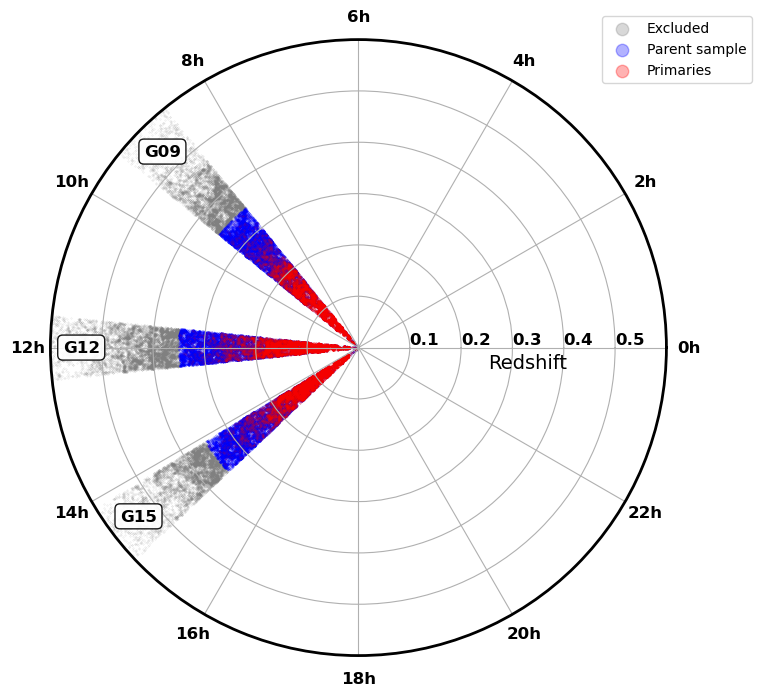

In [ ]:
# Plot a cone diagram of RA as the angle and redshift as the distance from the origin
fig, ax = plt.subplots(figsize = (8, 8), subplot_kw = {'projection': 'polar'})

# Flag each galaxy in the full catalogue as in the parent sample and/or in_sample
in_parent = np.asarray(keep, dtype = bool)
in_sample_cat = np.zeros(len(catalogue), dtype = bool)
in_sample_cat[np.where(in_parent)[0][np.asarray(parent['in_sample'])]] = True

theta = np.radians(np.asarray(catalogue['RA']))
r = np.asarray(catalogue['Z'])

# Plot the excluded galaxies first so the parent sample and primaries sit on top
excluded = ~in_parent
parent_only = in_parent & ~in_sample_cat
ax.scatter(theta[excluded], r[excluded], s = 0.05, alpha = 0.3, color = 'grey', label = 'Excluded', rasterized = True)
ax.scatter(theta[parent_only], r[parent_only], s = 0.05, alpha = 0.3, color = 'blue', label = 'Parent sample', rasterized = True)
ax.scatter(theta[in_sample_cat], r[in_sample_cat], s = 0.05, alpha = 0.3, color = 'red', label = 'Primaries', rasterized = True)

# Most of the catalogue lies below z = 0.6; the few galaxies beyond it fall outside the plot
R_MAX = 0.6
ax.set_rlim(0, R_MAX)
ax.set_rticks([0.1, 0.2, 0.3, 0.4, 0.5])
ax.set_rlabel_position(0) # Put the redshift labels along the 0h line
ax.set_xticks(np.radians(np.arange(0, 360, 30)))
ax.set_xticklabels([f'{h}h' for h in range(0, 24, 2)]) # RA in hours
ax.text(np.radians(-5), R_MAX * 0.55, 'Redshift', fontsize = 14, ha = 'center', va = 'center')

# Label each GAMA field at the outer end of its wedge
fields = {'G09': 135, 'G12': 180, 'G15': 217.5} # Central RA in degrees
for name, RA_centre in fields.items():
    ax.text(np.radians(RA_centre), R_MAX * 0.9, name, fontsize = 12, fontweight = 'bold', ha = 'center', va = 'center',
            bbox = dict(boxstyle = 'round', facecolor = 'white', edgecolor = 'black', alpha = 0.9))

ax.legend(markerscale = 40, loc = 'upper right', bbox_to_anchor = (1.15, 1.05))

bold_ticks(ax)

plt.savefig("figs/cone_diagram.pdf", format = "pdf", bbox_inches = "tight")
plt.savefig("figs/cone_diagram.png", format = "png", bbox_inches = "tight")

plt.show()

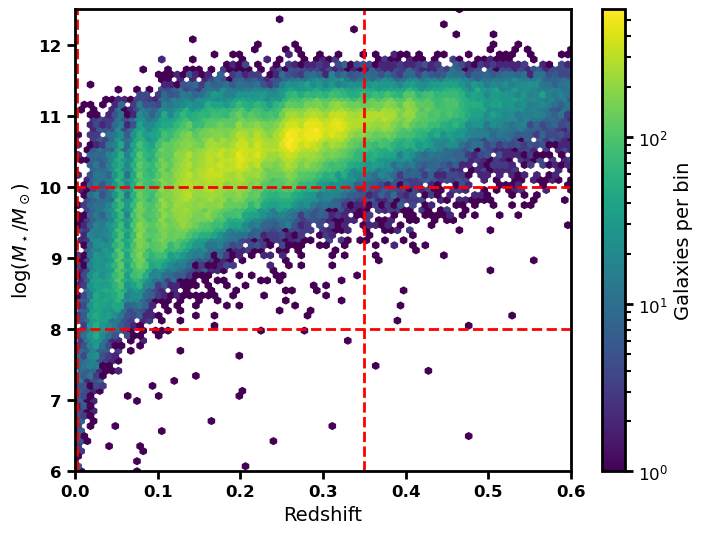

In [83]:
# Plot mass redshift distribution
fig, ax = plt.subplots(figsize = (8, 6))

hb = ax.hexbin(catalogue['Z'], catalogue['logmstar'], gridsize = 80, bins = 'log', extent = (0, 0.6, 6, 12.5), cmap = 'viridis')
fig.colorbar(hb, ax = ax, label = 'Galaxies per bin')

# Sample selection cuts
for z_cut in (Z_MIN, Z_MAX):
    ax.axvline(z_cut, color = 'red', linestyle = '--', linewidth = 2)

for logM_cut in (LOGM_MIN, LOGM_MAX):
    ax.axhline(logM_cut, color = 'red', linestyle = '--', linewidth = 2)

ax.set_xlim(0, 0.6)
ax.set_ylim(6, 12.5)
ax.set_xlabel('Redshift')
ax.set_ylabel(r'log($M_\star$/$M_\odot$)')

bold_ticks(ax)

plt.savefig("figs/mass_redshift.pdf", format = "pdf", bbox_inches = "tight")
plt.savefig("figs/mass_redshift.png", format = "png", bbox_inches = "tight")

plt.show()